# Dữ liệu hành vi khách hàng (Customer Behaviour)
**Nguồn trong đề:** Lab 2 — bài tập 2.3.3 (GaussianNB)

Notebook độc lập cho một tập dữ liệu; code lấy từ các ô tương ứng của notebook Lab2 (giữ nguyên, ô nào chỉnh có ghi `# [Chỉnh]`).

In [1]:
# Thư viện dùng chung (đề import rải rác ở nhiều ô; gom lại để notebook chạy độc lập)
import os
if os.path.basename(os.getcwd()) == 'notebooks':   # chạy notebook từ thư mục notebooks/ thì lùi ra thư mục gốc chứa data/
    os.chdir('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import matplotlib as mpl
import graphviz
from sklearn import tree, svm
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
cust = pd.read_csv('data/Customer_Behaviour.csv')
print(cust.shape)
print(cust.isnull().sum().sum(), "giá trị thiếu")
print(cust['Purchased'].value_counts())
cust.head()

(400, 5)
0 giá trị thiếu
Purchased
0    257
1    143
Name: count, dtype: int64


,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [3]:
# Đặc trưng: Age, EstimatedSalary; nhãn: Purchased (khách có mua hàng hay không)
Xc = cust[['Age','EstimatedSalary']].values
yc = cust['Purchased'].values
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.25, random_state=0, stratify=yc)
# Chuẩn hóa đặc trưng (fit trên tập train)
sc = StandardScaler()
Xc_tr = sc.fit_transform(Xc_tr); Xc_te = sc.transform(Xc_te)
gnb_c = GaussianNB()
gnb_c.fit(Xc_tr, yc_tr)
pred = gnb_c.predict(Xc_te)
print("Accuracy test: %.4f" % accuracy_score(yc_te, pred))
print(confusion_matrix(yc_te, pred))
print(classification_report(yc_te, pred, target_names=['Not purchased','Purchased']))

Accuracy test: 0.8500
[[58  6]
 [ 9 27]]
               precision    recall  f1-score   support

Not purchased       0.87      0.91      0.89        64
    Purchased       0.82      0.75      0.78        36

     accuracy                           0.85       100
    macro avg       0.84      0.83      0.83       100
 weighted avg       0.85      0.85      0.85       100



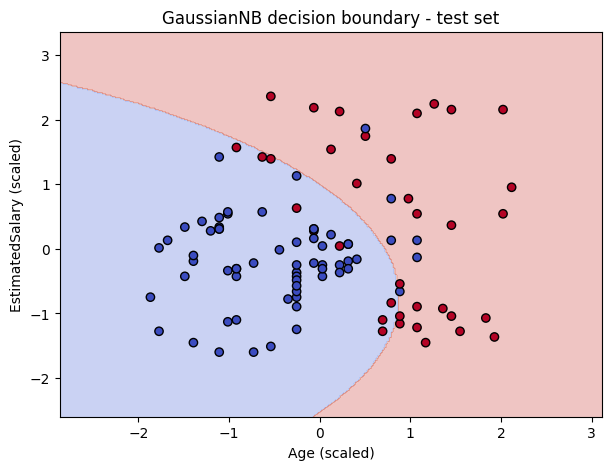

In [4]:
# Biên quyết định của Gaussian Naïve Bayes trên dữ liệu test (2 đặc trưng đã chuẩn hóa)
import matplotlib.pyplot as plt
xx, yy = np.meshgrid(np.linspace(Xc_te[:,0].min()-1, Xc_te[:,0].max()+1, 300),
                     np.linspace(Xc_te[:,1].min()-1, Xc_te[:,1].max()+1, 300))
zz = gnb_c.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
plt.figure(figsize=(7,5))
plt.contourf(xx, yy, zz, alpha=0.3, cmap='coolwarm')
plt.scatter(Xc_te[:,0], Xc_te[:,1], c=yc_te, cmap='coolwarm', edgecolor='k')
plt.xlabel('Age (scaled)'); plt.ylabel('EstimatedSalary (scaled)')
plt.title('GaussianNB decision boundary - test set')
plt.show()